In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from sklearn.metrics import r2_score
from scipy.stats import norm

# Загрузка данных
df = pd.read_csv('data.csv', sep=';')

# Преобразование даты в формат datetime
df['start_date_time'] = pd.to_datetime(df['start_date_time'])

# Пункт 2: Формирование матриц X и Y
# X - время в днях
X = (df['start_date_time'] - df['start_date_time'].min()).dt.days.values
# Y - данные нейтронного монитора
Y = df['1HCOR_E'].values

print(f"Загружено {len(X)} точек данных.")
print(f"Диапазон дат: с {df['start_date_time'].min().date()} по {df['start_date_time'].max().date()}")

Загружено 343 точек данных.
Диапазон дат: с 2015-01-01 по 2015-12-31


In [7]:
# Определение нелинейной функции (синусоида)
def modelfun(x, A, B, T, phi):
    # x - время в днях, T - период в днях
    return A + B * np.sin((2 * np.pi * x) / T + phi)

# Задание начальных приближений (beta0)
# A - среднее значение, B - половина размаха, T - примерно 365 дней (годовой цикл), phi - 0
beta0 = [np.mean(Y), (np.max(Y) - np.min(Y)) / 2, 365, 0]

# Реализация нелинейной регрессии
# curve_fit возвращает оптимальные параметры (beta) и ковариационную матрицу
beta, covariance = curve_fit(modelfun, X, Y, p0=beta0, maxfev=10000)

print("Полученные коэффициенты модели (beta):")
print(f"A (смещение): {beta[0]:.4f}")
print(f"B (амплитуда): {beta[1]:.4f}")
print(f"T (период, дней): {beta[2]:.4f}")
print(f"phi (фаза, рад): {beta[3]:.4f}")

Полученные коэффициенты модели (beta):
A (смещение): 184.7539
B (амплитуда): -2.7720
T (период, дней): 503.1751
phi (фаза, рад): 0.6761


Коэффициент детерминации R^2: 0.4260


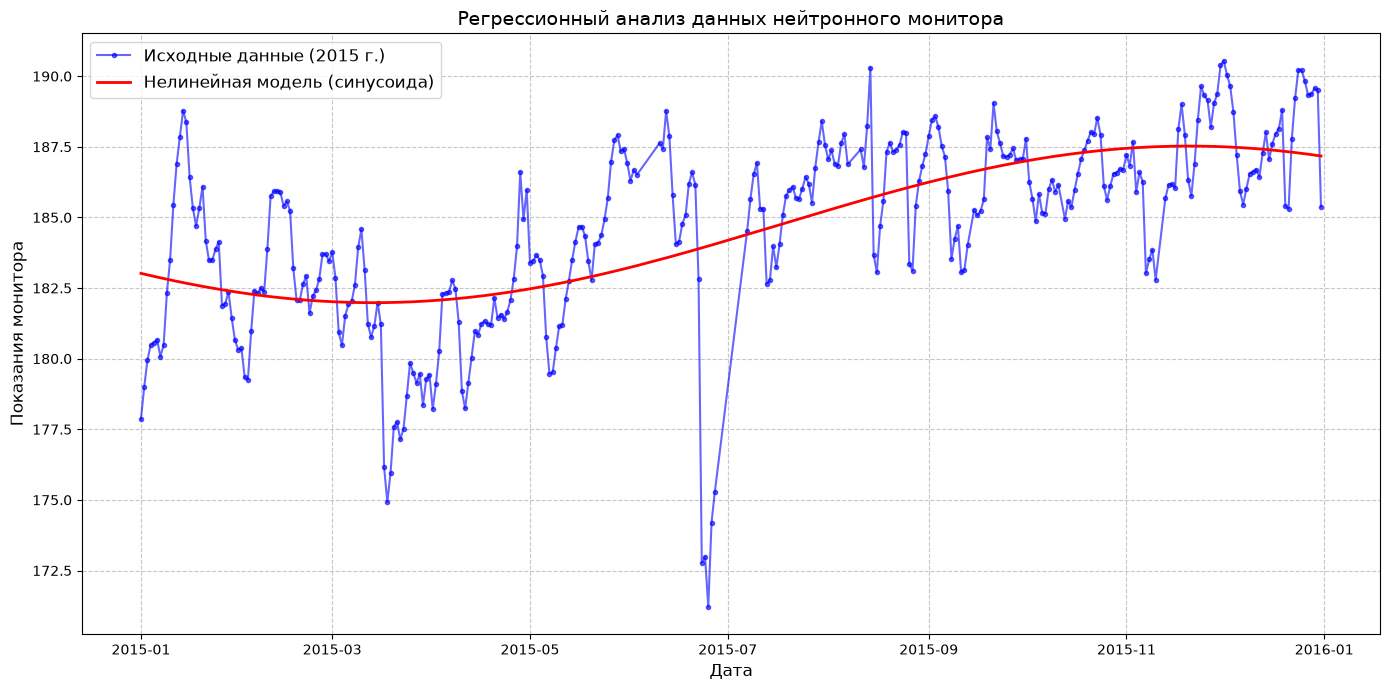

In [19]:
# Получение предсказанных значений
Y_pred = modelfun(X, *beta)

# Оценка качества модели (коэффициент детерминации R^2)
r2 = r2_score(Y, Y_pred)
print(f"Коэффициент детерминации R^2: {r2:.4f}")

# Построение графиков
plt.figure(figsize=(14, 7))
plt.plot(df['start_date_time'], Y, label='Исходные данные (2015 г.)', color='blue', alpha=0.6, marker='.', linestyle='-')
plt.plot(df['start_date_time'], Y_pred, label='Нелинейная модель (синусоида)', color='red', linewidth=2)

plt.title('Регрессионный анализ данных нейтронного монитора', fontsize=14)
plt.xlabel('Дата', fontsize=12)
plt.ylabel('Показания монитора', fontsize=12)
plt.legend(fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig('plot_1_regression.png', dpi=300, bbox_inches='tight')
plt.show()

Среднее значение ошибок (сдвиг): 0.0000
Стандартное отклонение ошибок (разброс): 2.5322


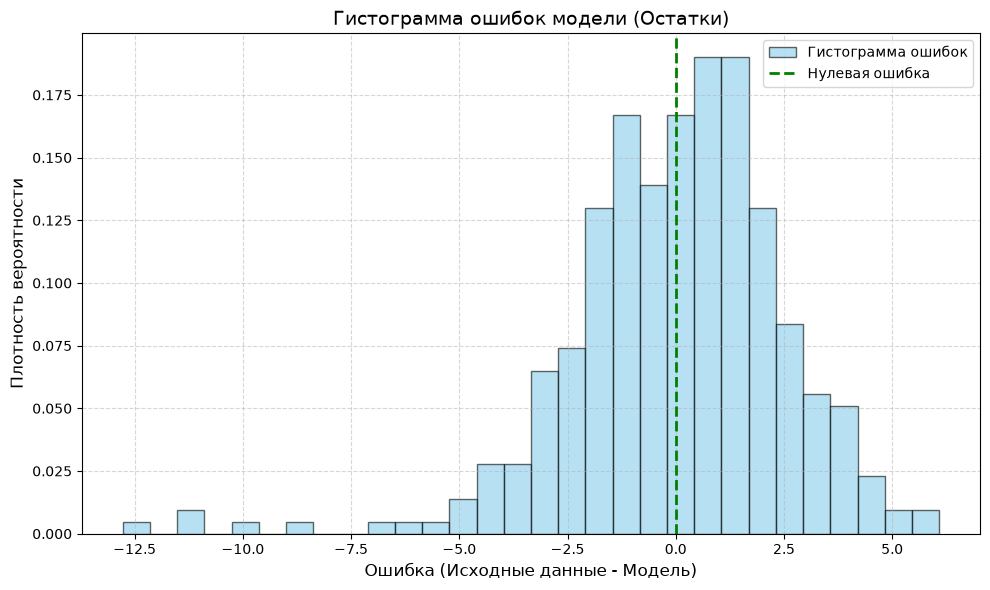

In [18]:
# 1. Вычисление остатков
# Остатки = Реальное значение - Предсказанное значение
residuals = Y - Y_pred

# 2. Расчет статистик ошибок
mean_res = np.mean(residuals)
std_res = np.std(residuals)

print(f"Среднее значение ошибок (сдвиг): {mean_res:.4f}")
print(f"Стандартное отклонение ошибок (разброс): {std_res:.4f}")

# 3. Построение гистограммы
plt.figure(figsize=(10, 6))

count, bins, ignored = plt.hist(residuals, bins=30, density=True, alpha=0.6, color='skyblue', edgecolor='black', label='Гистограмма ошибок')


plt.title('Гистограмма ошибок модели (Остатки)', fontsize=14)
plt.xlabel('Ошибка (Исходные данные - Модель)', fontsize=12)
plt.ylabel('Плотность вероятности', fontsize=12)
plt.axvline(0, color='green', linestyle='--', linewidth=2, label='Нулевая ошибка')
plt.legend(fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('plot_2_histogram.png', dpi=300, bbox_inches='tight')
plt.show()